# CCE 3503 - Practical Machine Learning 
## Assignment 1: Feature Analysis
#### Name: Dave Galea
#### Student ID: 0283404L

***Additional library used:*** Feature-engine

The above library Feature-engine was used for random imputation using observed values, since scikit-learn's SimpleImputer does not provide this method. The library provides a ready-made imputer compatible with scikit-learn pipelines, avoiding the need to write a custom transformer. For consistency, even though this library was only needed for Random imputation, it was also used for median and mean imputations.

Feature-engine is open source under the BSD 3-Clause licence, free for commercial and non-commercial use, and has stable, maintained releases.
Documentation: https://feature-engine.trainindata.com/

In [75]:
%pip install -q feature-engine

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
import numpy as np
import scipy as sp
import seaborn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, cross_val_score
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from feature_engine.imputation import MeanMedianImputer, RandomSampleImputer
import matplotlib.pyplot as plt

## Task 1: Data cleaning, missing data, and normalization (+splitting)

Note: the above task has been modified to include the splitting from task 2 so to avoid data leakage.

In [60]:
raw_data = pd.read_csv("labelled.csv")
raw_data.head(10) # just getting an feel of the data

,id,new_tool_adoption_speed,code_review_effectiveness,attention_to_detail_score,empathy_rating_peer_avg,workload_capacity_rating,leadership_potential_rating,quantitative_analysis_score,communication_clarity_index,domain_knowledge_score,...,task_logging_completeness_rate,response_time_internal_comms_avg_hrs,task_decomposition_skill,perseverance_metric_avg_days,desk_location_zone_encoded,customer_support_rating_avg,internal_newsletter_open_rate,error_rate_reduction_percent,employee_discount_usage_rate,performance_score
0,8001,23,2.60,2.18,4.11,30.5,2.52,19.8,3.14,6.2,...,22.1,3.9,1.38,4.0,101,3.58,12.3,33.2,87.9,58.16
1,8002,11,3.97,3.52,4.26,66.1,3.41,64.3,4.29,21.2,...,62.7,2.1,2.34,7.0,102,4.38,10.4,66.5,31.6,84.12
2,8003,16,3.18,3.17,3.56,53.3,3.08,47.7,3.31,37.1,...,64.3,3.2,2.59,5.1,202,3.55,72.4,54.7,96.8,72.94
3,8004,16,3.03,3.65,3.05,59.9,3.39,41.2,2.89,68.7,...,75.1,2.0,3.38,5.8,201,3.65,53.9,64.5,48.5,51.76
4,8005,18,2.27,3.09,1.59,48.7,2.15,37.7,1.79,41.7,...,70.8,4.1,2.59,5.5,202,2.24,75.4,51.4,93.9,58.08
5,8006,8,4.36,2.93,5.00,74.4,4.03,78.2,4.66,45.2,...,70.6,1.9,3.20,5.3,201,4.53,83.9,73.4,65.1,64.86
6,8007,7,3.79,2.13,1.97,69.9,2.98,86.6,3.60,29.7,...,56.9,4.2,2.89,4.7,301,2.95,61.9,65.7,82.6,62.30
7,8008,26,2.19,1.00,3.60,9.3,2.66,15.5,3.03,18.3,...,0.0,6.4,1.72,1.0,102,2.80,60.1,7.8,55.7,57.49
8,8009,11,2.87,3.35,1.44,62.8,3.02,64.7,2.25,79.3,...,81.9,4.3,4.01,5.3,202,2.19,44.2,62.3,99.0,76.93
9,8010,19,2.93,2.97,4.49,45.6,3.04,32.5,3.21,35.0,...,58.7,2.9,2.34,5.4,101,3.75,58.6,48.9,23.4,60.87


### Subtask 1: Remove the non-predictive features and the potential target features from the dataset.

In [61]:
clean_data = raw_data.copy()

# Remove the non predictive features and target features
non_predictive = [
    "id", 
    "laptop_serial_number_last_digit", 
    "parking_bay_number",
    ]
target = [
    "performance_score",
    "manager_discretionary_bonus_count"
    ]

features_to_remove = non_predictive + target

clean_data = clean_data.drop(columns = features_to_remove)

clean_data.head(10)


,new_tool_adoption_speed,code_review_effectiveness,attention_to_detail_score,empathy_rating_peer_avg,workload_capacity_rating,leadership_potential_rating,quantitative_analysis_score,communication_clarity_index,domain_knowledge_score,first_pass_yield_rate,...,work_consistency_metric_std,task_logging_completeness_rate,response_time_internal_comms_avg_hrs,task_decomposition_skill,perseverance_metric_avg_days,desk_location_zone_encoded,customer_support_rating_avg,internal_newsletter_open_rate,error_rate_reduction_percent,employee_discount_usage_rate
0,23,2.60,2.18,4.11,30.5,2.52,19.8,3.14,6.2,35.9,...,6.99,22.1,3.9,1.38,4.0,101,3.58,12.3,33.2,87.9
1,11,3.97,3.52,4.26,66.1,3.41,64.3,4.29,21.2,66.9,...,3.66,62.7,2.1,2.34,7.0,102,4.38,10.4,66.5,31.6
2,16,3.18,3.17,3.56,53.3,3.08,47.7,3.31,37.1,56.0,...,5.85,64.3,3.2,2.59,5.1,202,3.55,72.4,54.7,96.8
3,16,3.03,3.65,3.05,59.9,3.39,41.2,2.89,68.7,69.1,...,5.29,75.1,2.0,3.38,5.8,201,3.65,53.9,64.5,48.5
4,18,2.27,3.09,1.59,48.7,2.15,37.7,1.79,41.7,54.1,...,5.38,70.8,4.1,2.59,5.5,202,2.24,75.4,51.4,93.9
5,8,4.36,2.93,5.00,74.4,4.03,78.2,4.66,45.2,72.4,...,5.71,70.6,1.9,3.20,5.3,201,4.53,83.9,73.4,65.1
6,7,3.79,2.13,1.97,69.9,2.98,86.6,3.60,29.7,61.4,...,6.24,56.9,4.2,2.89,4.7,301,2.95,61.9,65.7,82.6
7,26,2.19,1.00,3.60,9.3,2.66,15.5,3.03,18.3,6.4,...,10.00,0.0,6.4,1.72,1.0,102,2.80,60.1,7.8,55.7
8,11,2.87,3.35,1.44,62.8,3.02,64.7,2.25,79.3,61.8,...,5.62,81.9,4.3,4.01,5.3,202,2.19,44.2,62.3,99.0
9,19,2.93,2.97,4.49,45.6,3.04,32.5,3.21,35.0,52.1,...,5.56,58.7,2.9,2.34,5.4,101,3.75,58.6,48.9,23.4


#### A short comment on the above: 

##### Non predictive features
| Feature | Reason for removing |
| -------- | ------- |
| Id  |  The ID is unique for every single person, and has no effect on performance   |
| laptop_serial_number_last_digit | The last digit of a serial number is random for every person and has no effect on performance.     |
| parking_bay_number    |  Since we have no information of the parking layout (Some companies have it that certain areas are for different ranking employees), and the feature contains individual parking bay numbers rather than defined groups or zones, we can treat these numbers as effectively random identifiers with little expected effect on performance. This differs from desk_location_zone_encoded, which explicitly groups employees into zones; had the parking bay feature been recorded as, for example, "Area X" or "Level X", the feature would have been retained. |

Since the rules used to generate the synthetic dataset are unknown, my decision to remove features was not based on simply appearing unrelated to perfromance (for example, favourite colour does appear unrelated to performance). Instead, they were removed based on the fact that they act as identifiers (id, serial numbers), or that they are simply arbitrary numbers (parking bay number); any apparent relationship with the performance score would simply be misleading in these cases. 

##### Potential Target Features
| Feature | Reason for removing |
| -------- | ------- |
| performance_score | Target Feature stated in the assignment description (not a potential target feature; just the target feature) |
| manager_discretionary_bonus_count | If bonuses are awarded based on the performance score, then we are using information that we not have access to at prediction time, thus causing data leakage. However, if bonuses are awarded before the final performance evaluation, the feature could be a valid predictor. Since the timing is unknown, I chose to exclude this feature so to err on the safer side. 

Other features, such as 360_feedback_score_avg, could also potentially introduce target leakage if they are dependent on an employee's performance_score. However, the rules used to generate the synthetic dataset are unknown, so this cannot be confirmed. I considered manager_discretionary_bonus_count a greater potential risk because, in my opinion,it is the feature most likely to be influenced by the final performance score. 

### Subtask 2: Randomly split the dataset into a train subset and test subset using an appropriate ratio of train subset samples to test subset samples. Comment on the choice of ratio.

In [62]:
X = clean_data # input features
y = raw_data["performance_score"] # target feature

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 4
)

Since we are going to be using wrapping methods, which typically use cross-validation, we use an 80/20 split which is the a common choice for when separate validation set is not used. This leaves 20% of the dataset (1000 rows in this case) left for testing the model at the end. 

### Subtask 3: Use appropriate techniques to handle features with missing data. Comment on why you selected the techniques used for missing data, and any adverse effect they may have on the data.

In [63]:
# First we see how much missing data we have in our dataset 
# how many employees have missing data?

# employees with at least one missing feature
employees_with_missing = (X_train == "?").any(axis=1).sum()

# employees with no missing features
employees_complete = (~(X_train == "?").any(axis=1)).sum()

print("Total employees:", len(X_train))
print("Employees with missing values:", employees_with_missing)
print("Employees with complete data:", employees_complete)


Total employees: 4000
Employees with missing values: 2910
Employees with complete data: 1090


From the above we know that elimination of all rows with a missing value is simply not an option. We can look into which features have the most missing values, and see if one feature is causing the discrepancy. 

In [64]:
# which features have missing data, and how much do they have missing?
missing_count = (X_train == "?").sum(axis=0)

missing_count = missing_count[missing_count > 0].sort_values(ascending=False)

print(missing_count.to_string())


favourite_music_genre           1697
commute_time_minutes             610
360_feedback_score_avg           604
client_satisfaction_score        389
technical_assessment_score       286
age                              208
on_time_task_completion_rate     198
sex                              163
team_collaboration_rating        156
avg_hours_worked_per_week        117


From the above, I have made the following decisions: 
- favourite_music_genre: remove the feature entirely. Although music taste could potentially have some indirect relationship with performance, with such high amount of missing data, imputing nearly half of the feature could significantly distort its original distribution. 
    - *Adverse effect*: removes any potential predictive power that the feature may have

- For the rest of the numerical features I will examine the distributions of each:
    - If the distribution is skewed, I will use the **median** for imputation as it is less affected by extreme values. 
        - *Adverse effect*: Can reduce variance and create an artificially concentrated area of values around the median

    - If the distribution is approximately symmetric, I will use the **mean**, as it represents the centre of data well. 
        - *Adverse effect*: Can reduce variance and create an artificially concentrated area of values around the mean.

    - If the distribution is approximately uniform, I will use **random** imputation using observed values, as this preserves the feature's overall distribution. Kurtosis will also be checked to support this. 
        - *Adverse effect*: Introduces randomness which may weaken relationships of the imputed feature with other features.

- For the categorical feature sex, I will see the ratio M and F currently have. If they are quite balanced, I will use **Random** imputation using observed values. Otherwise, I will use **Mode** imputation to fill in with the most dominant category.
    - *Adverse effect (Random)*: As stated above: Introduces randomness which may weaken relationships of the imputed feature with other features.
    - *Adverse effect (Mode)*: May exxagerate any existing imbalances present in the categorical data.

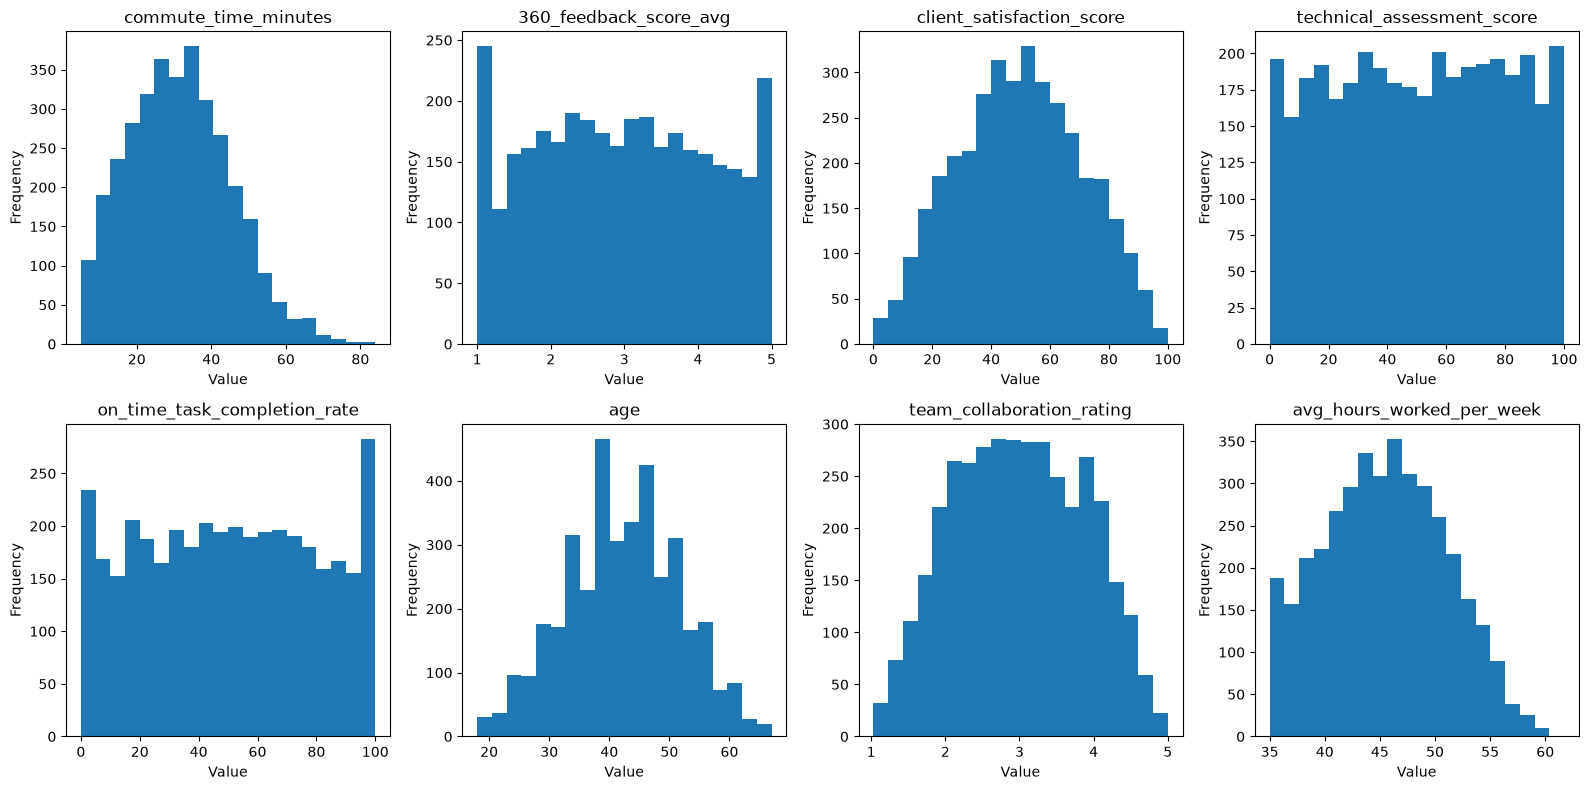

Skewness:
commute_time_minutes            0.361057
360_feedback_score_avg          0.032668
client_satisfaction_score       0.011022
technical_assessment_score     -0.025082
on_time_task_completion_rate    0.010178
age                            -0.032816
team_collaboration_rating       0.024096
avg_hours_worked_per_week       0.087215

Kurtosis:
commute_time_minutes           -0.174073
360_feedback_score_avg         -1.094221
client_satisfaction_score      -0.702135
technical_assessment_score     -1.177611
on_time_task_completion_rate   -1.129288
age                            -0.355886
team_collaboration_rating      -0.872346
avg_hours_worked_per_week      -0.670399


sex
M      1962
F      1875
NaN     163
Name: count, dtype: int64


In [65]:
# Drop the favourite_music_genre feature
features_to_remove.append("favourite_music_genre")
X_train = X_train.drop(columns = ["favourite_music_genre"])
X_test = X_test.drop(columns = ["favourite_music_genre"])


# Convert missing-value markers to NaN
X_train = X_train.replace("?", np.nan)
X_test = X_test.replace("?", np.nan)

# Numerical features with missing values
numeric_features = [
    "commute_time_minutes",
    "360_feedback_score_avg",
    "client_satisfaction_score",
    "technical_assessment_score",
    "on_time_task_completion_rate",
    "age",
    "team_collaboration_rating",
    "avg_hours_worked_per_week"
]

numeric_data = X_train[numeric_features].apply(pd.to_numeric)
# Plot the distributions
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for feature, ax in zip(numeric_features, axes.flat):
    ax.hist(numeric_data[feature].dropna(), bins=20)
    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# Calculate skewness and kurtosis for each numerical feature
skewness = numeric_data.skew()
kurtosis = numeric_data.kurt()

print("Skewness:")
print(skewness.to_string())

print("\nKurtosis:")
print(kurtosis.to_string())

# Categorical data handling 
print("\n")
print(X_train["sex"].value_counts(dropna=False))



From the above histograms, kurtosis values, skenwess values, and categorical distributions, the following decisions will apply:

To be imputed with **Mean** imputation (low skewness): 
- client_satisfaction_score
- age
- team_collaboration_rating
- avg_hours_worked_per_week (although seems visually skewed, numerically it is only very slightly skewed)

To be imputed with **Median** imputation (positive skewness):
- commute_time_minutes

To be imputed with **Random** imputation (approximately uniform distribution):
- on_time_task_completion_rate
- 360_feedback_score_avg
- technical_assesment_score
- sex: the M and F categories are roughly equal in distribution.

In [66]:
mean_features = [
    "client_satisfaction_score",
    "age",
    "team_collaboration_rating",
    "avg_hours_worked_per_week"
]

median_features = [
    "commute_time_minutes"
]

random_features = [
    "on_time_task_completion_rate",
    "360_feedback_score_avg",
    "technical_assessment_score",
    "sex"
]

print(X_train[numeric_features].dtypes) # check types to see if we need to convert

# change to numerical types
X_train[numeric_features] = X_train[numeric_features].apply(pd.to_numeric)
X_test[numeric_features] = X_test[numeric_features].apply(pd.to_numeric)

'''
using a pipeline so that imputation is then done during validation 
rather than before so to prevent data leakage
'''
imputation_pipeline = Pipeline([
    ("mean", MeanMedianImputer(imputation_method = "mean", variables = mean_features)),
    ("median", MeanMedianImputer(imputation_method = "median", variables = median_features)),
    ("random", RandomSampleImputer(variables = random_features, random_state = 4))
])

commute_time_minutes            str
360_feedback_score_avg          str
client_satisfaction_score       str
technical_assessment_score      str
on_time_task_completion_rate    str
age                             str
team_collaboration_rating       str
avg_hours_worked_per_week       str
dtype: object


### Subtask 4: Normalize the data using an appropriate mechanism. Comment on the mechanism used and why you selected it.

Before normalizing the data, we must first one-hot encode the categorical features in the dataset: sex and department. Additionally, I will apply one-hot encoding to previously encoded categorical features that have no natural order, to avoid introducing false mathematical relationships between their values.

The choice to not re-encode company_merch_size_encoded is because clothing sizes do have a natural order, meaning its existing ordinal encoding may be appropriate given that 1 represents a smaller size than 4. 

In [67]:

categorical_features = [
    "sex",
    "department", 
    "favourite_colour_encoded", 
    "desk_location_zone_encoded"
]

# Encode categorical features
encoding = ColumnTransformer(
    transformers = [
        ("categorical", OneHotEncoder(
            categories = [
                ["F", "M"],
                ["Engineering", "Finance", "Operations", "Product", "Sales"],
                [1,2,3,4,5],
                [101, 102, 201, 202, 301] 
            ],
            drop = "if_binary", # create only one column for sex since its binary 
            handle_unknown = "ignore",
            sparse_output = False
        ), categorical_features)
    ],
    remainder = "passthrough", # dont change the other numerical columns
    verbose_feature_names_out = False # prevent the prefixes ColumnTransformer adds 
)

Regarding normalization, I have chosen to normalize using Min-Max scaling, which scales the training features to the range 0 to 1, preventing features with larger numerical ranges from dominating those with smaller ranges. The choice of scaling to the range 0 to 1 is particularly useful because it preserves the binary values produced by one-hot encoding; had another normalization method been used,  I would have applied it only to the numerical features, leaving the one-hot encoded categorical features unchanged to preserve their binary representation.

MinMax scaling does have its limitations however:

- *Sensitivity to outliers*: The 0 and 1 are determined by the absolute minimums and maximmums of each feature in the training set; and if these are extreme values, differences between observations will be undermined. 
- *Need for Extrapolation*: If the test set eventually has values higher or lower than these minimums and maximums found from the training set, values outside of the 0 to 1 range will occur. This causes extrapolation, potentially reducing prediction accuracy. 

One should also note that since PCA requires standardization rather than normalization, in later tasks when comparison between them is made, differences in results may be partially attributed to the different scaling method; as the Filter Methods and Wrapper Methods will use normalization whilst PCA will use standardization. 

In [68]:
# add to our current pipeline
preprocessing_pipeline = Pipeline([
    ("imputation", imputation_pipeline),
    ("encoding", encoding),
    ("normalization", MinMaxScaler()) # perform normalization on all (categorical remain effectively unchanged)
])

## Task 2: Filter methods (-splitting)

### Subtask 1: Obtain a colour coded correlation matrix for the remaining features (for example using the pandas corr function and the seaborn heatmap function).

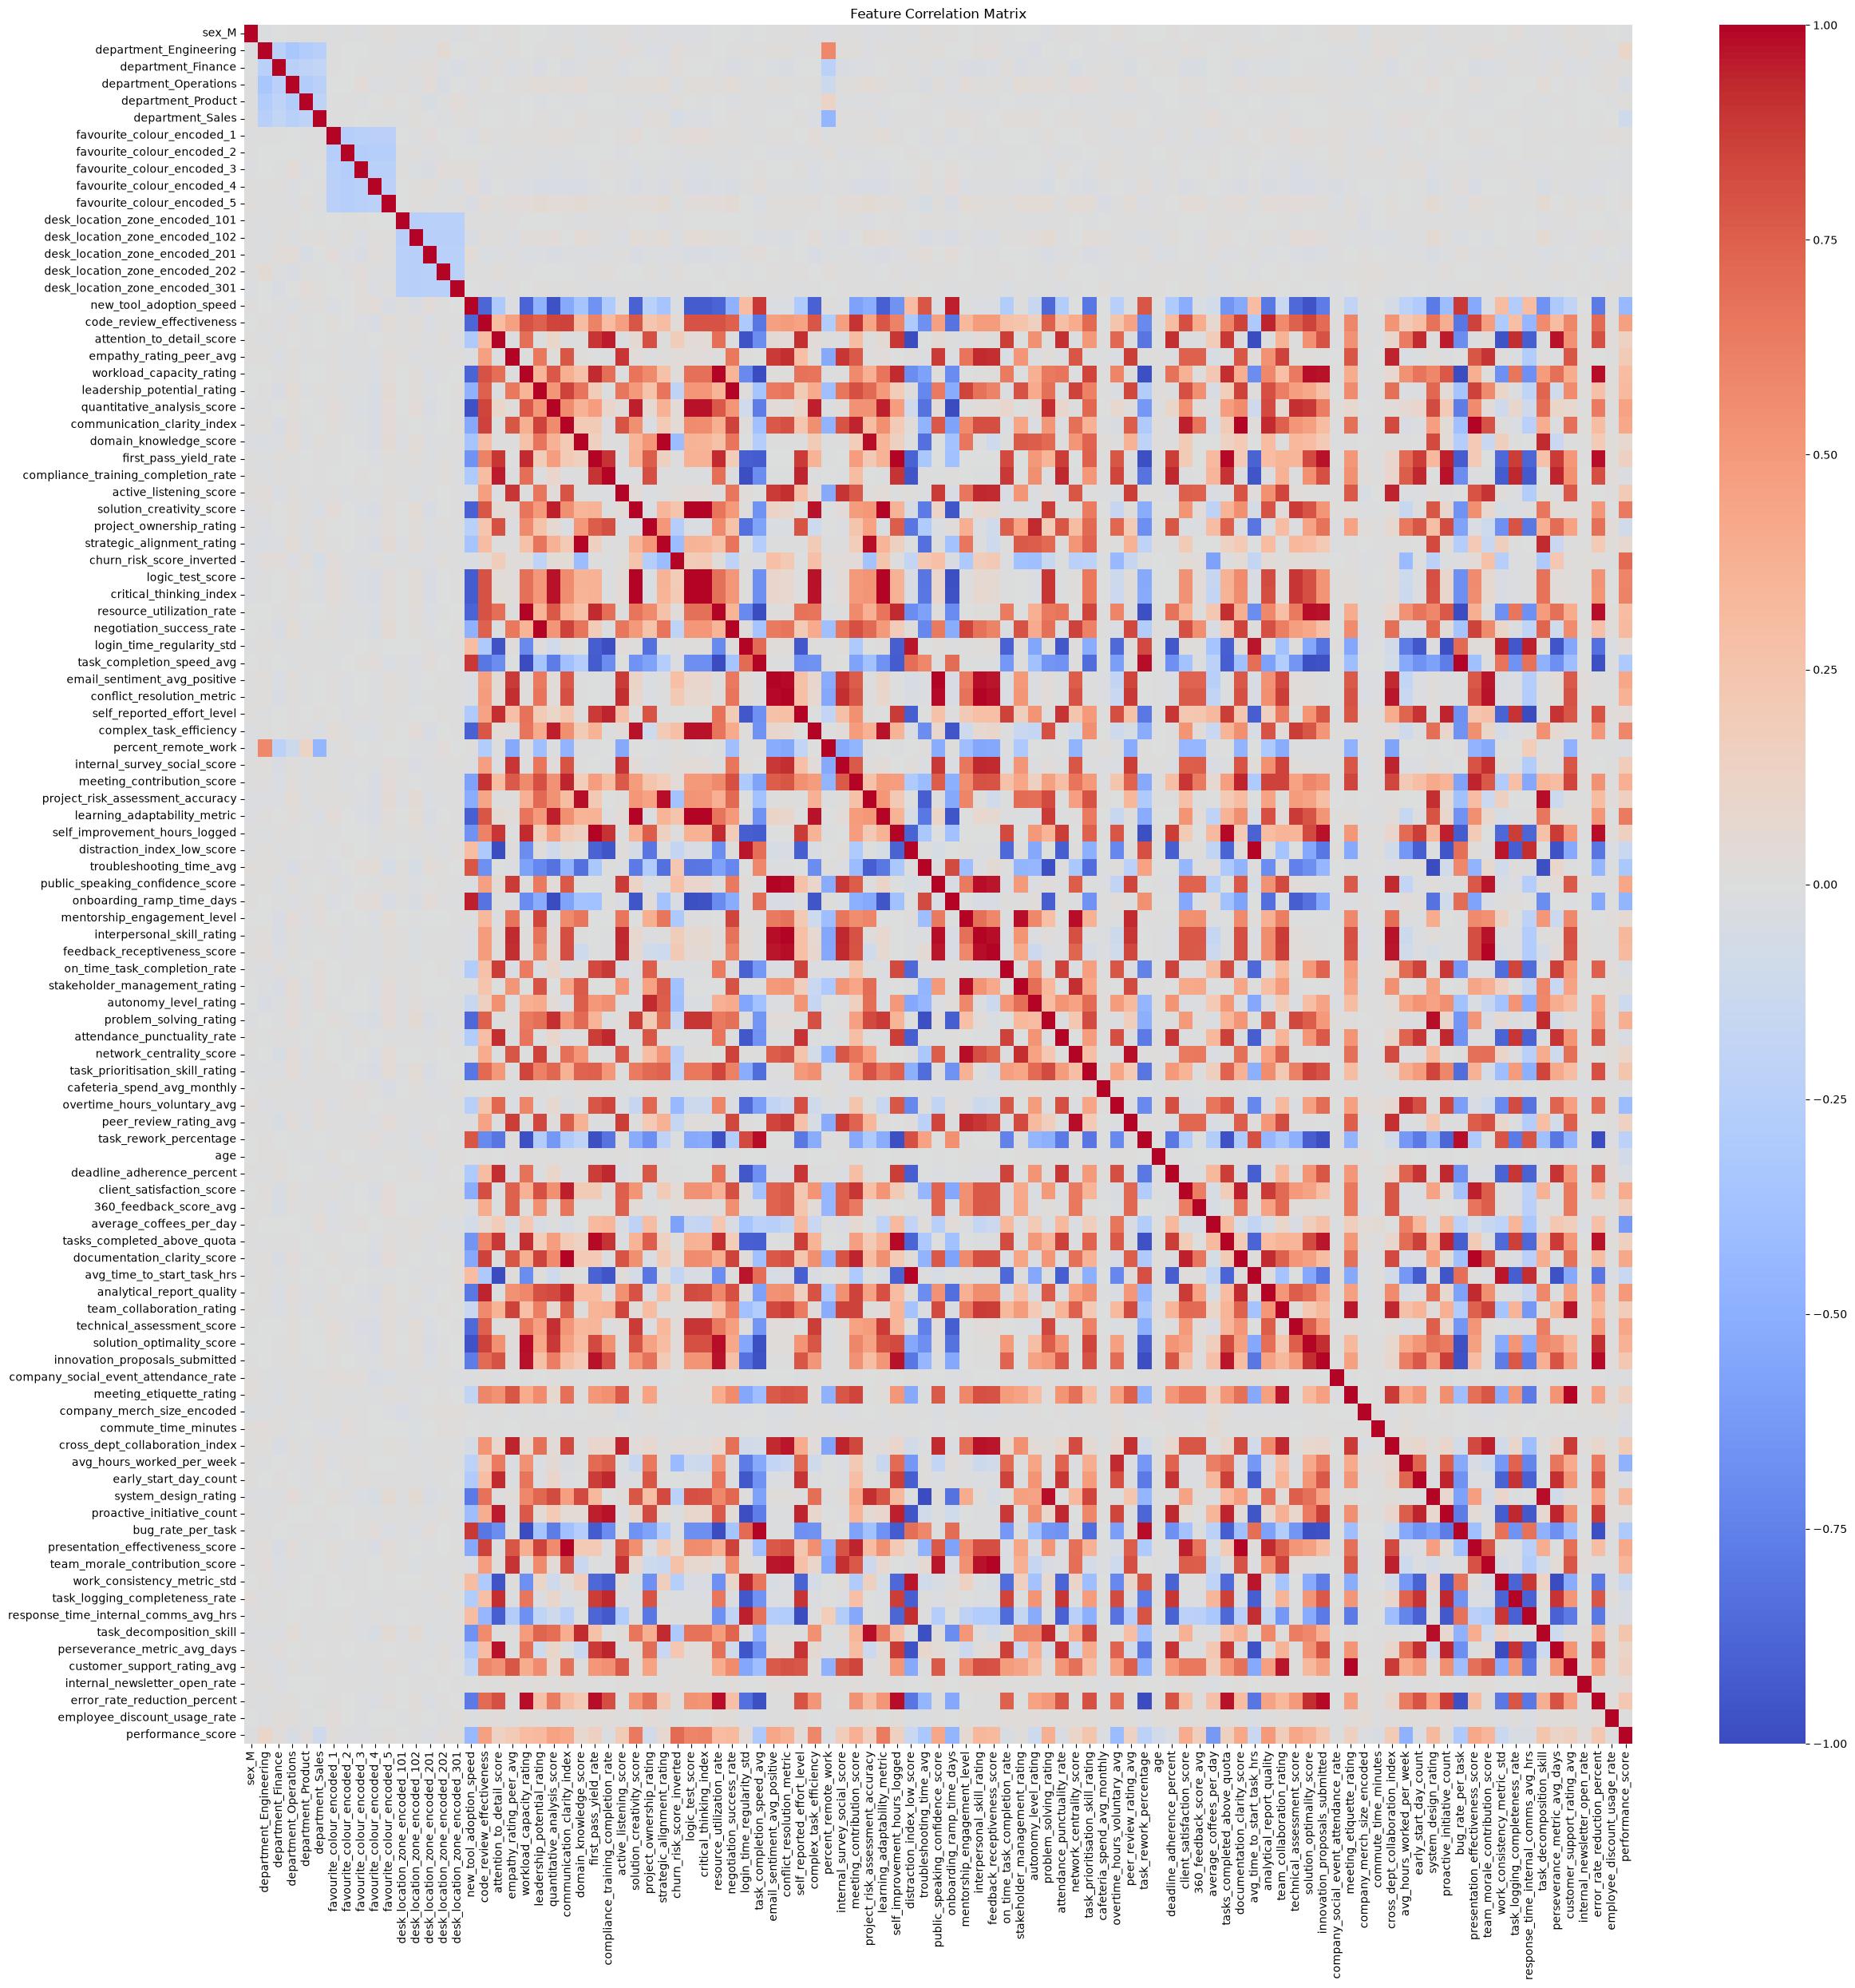

In [69]:
preprocessing_filter = clone(preprocessing_pipeline)

X_train_filter_preprocessed = preprocessing_filter.fit_transform(X_train)
X_test_filter_preprocessed = preprocessing_filter.transform(X_test)

filter_feature_names = preprocessing_filter.named_steps["encoding"].get_feature_names_out()

correlation_data = pd.DataFrame(
    X_train_filter_preprocessed,
    columns = filter_feature_names,
    index = X_train.index
)
# add back target feature 
correlation_data["performance_score"] = y_train

# calculate Pearson correlation coefficients
correlations = correlation_data.corr()

# plot the correlation matrix
plt.figure(figsize=(25,25))

seaborn.heatmap(
    correlations,
    cmap = "coolwarm",
    vmin = -1,
    vmax = 1,
    center = 0,
    xticklabels = 1,
    yticklabels = 1
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

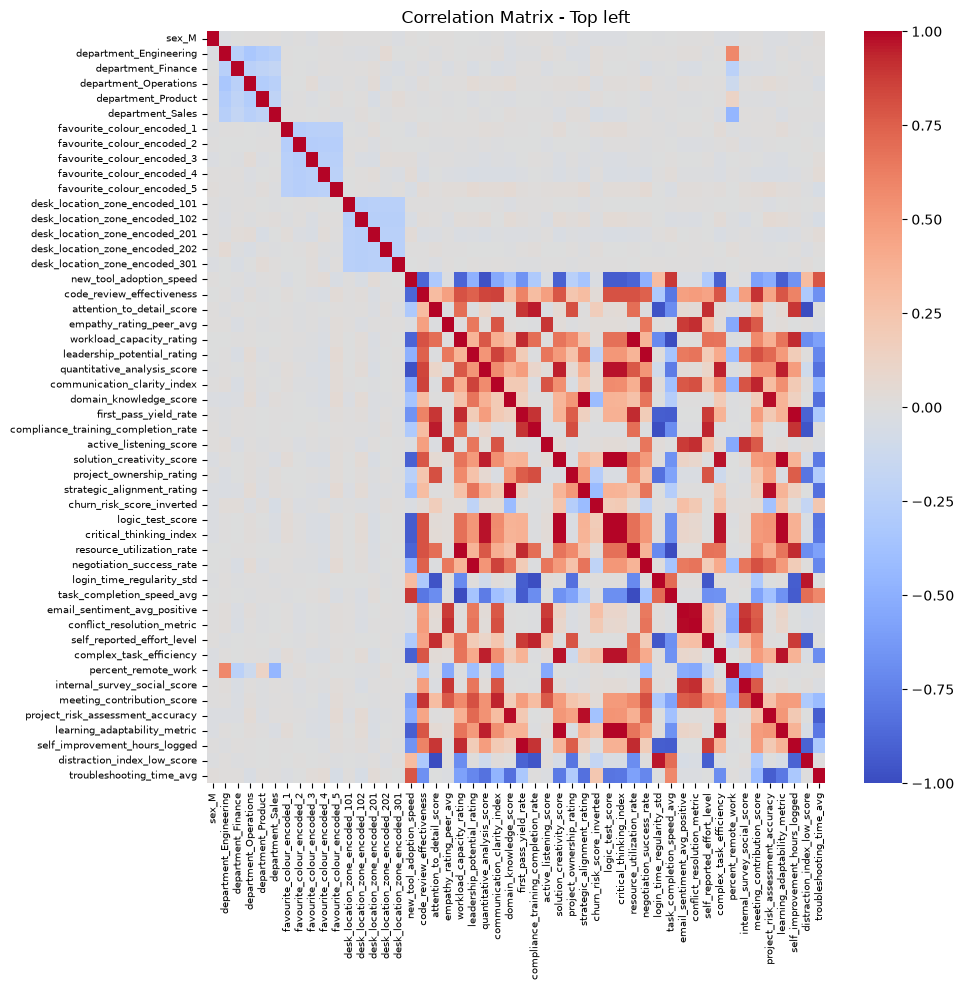

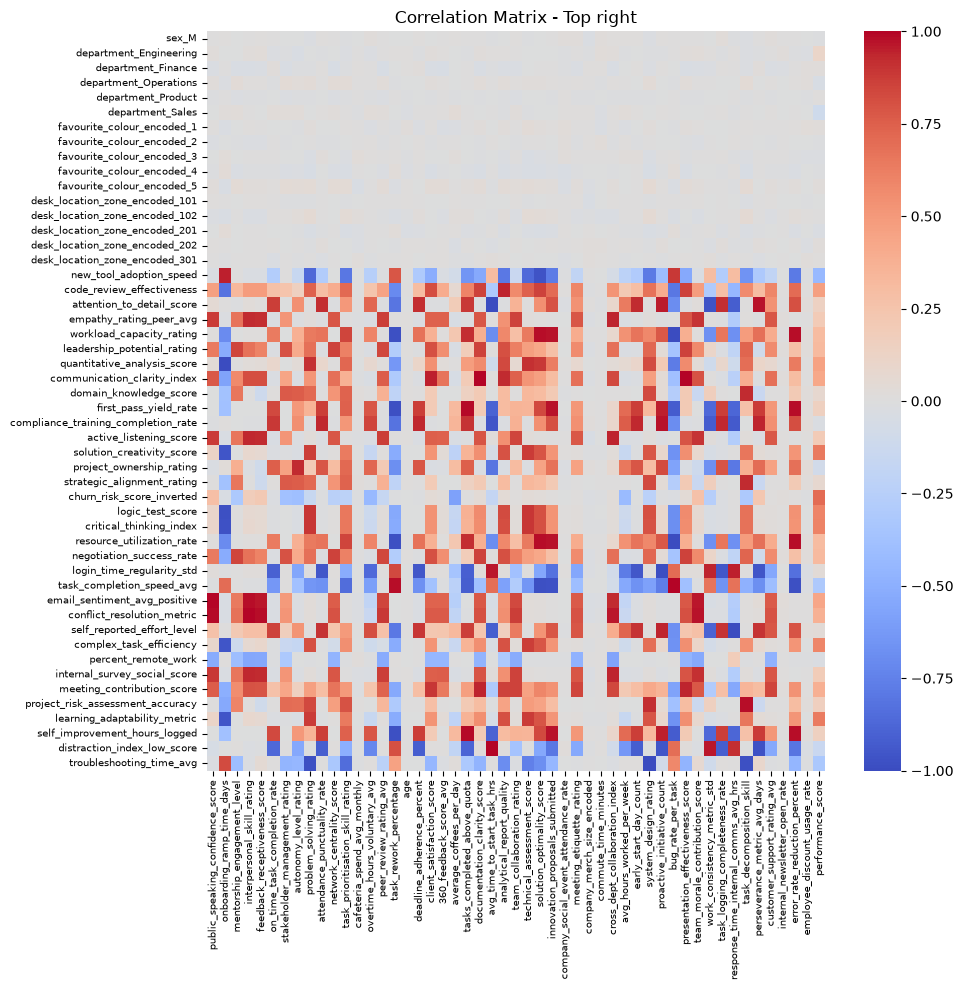

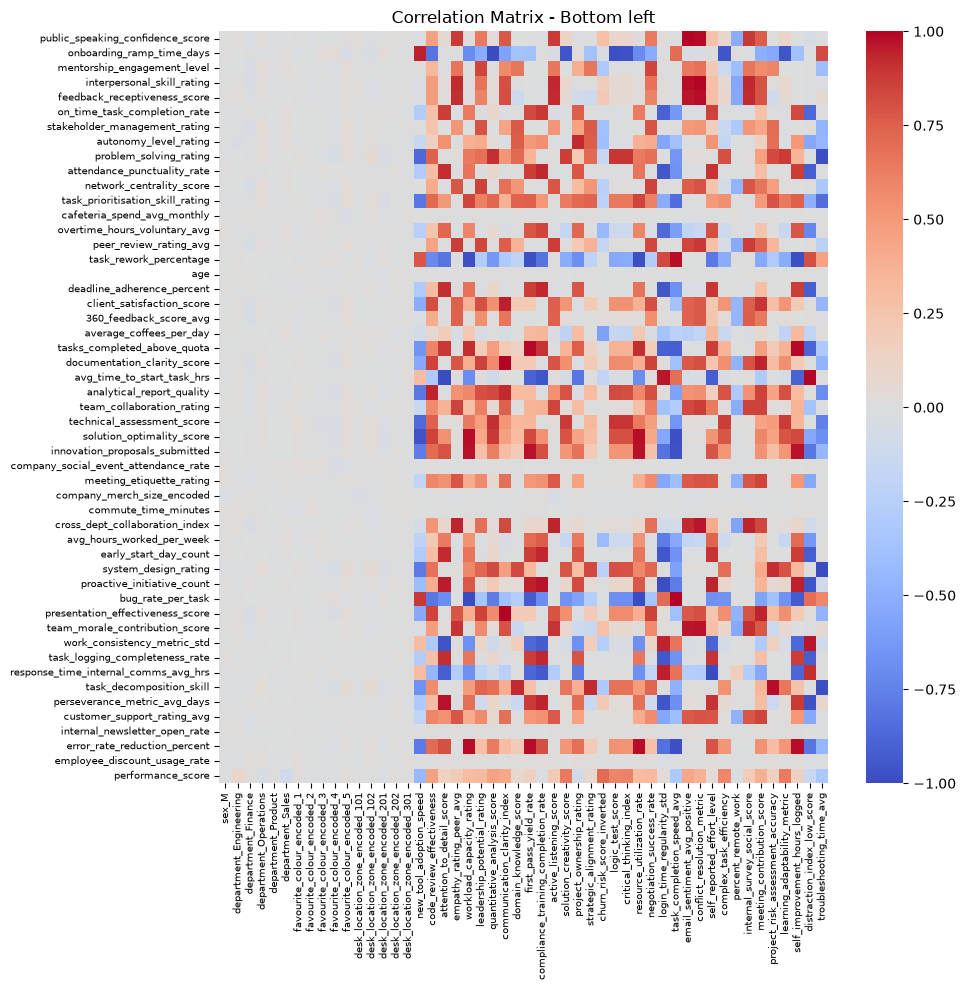

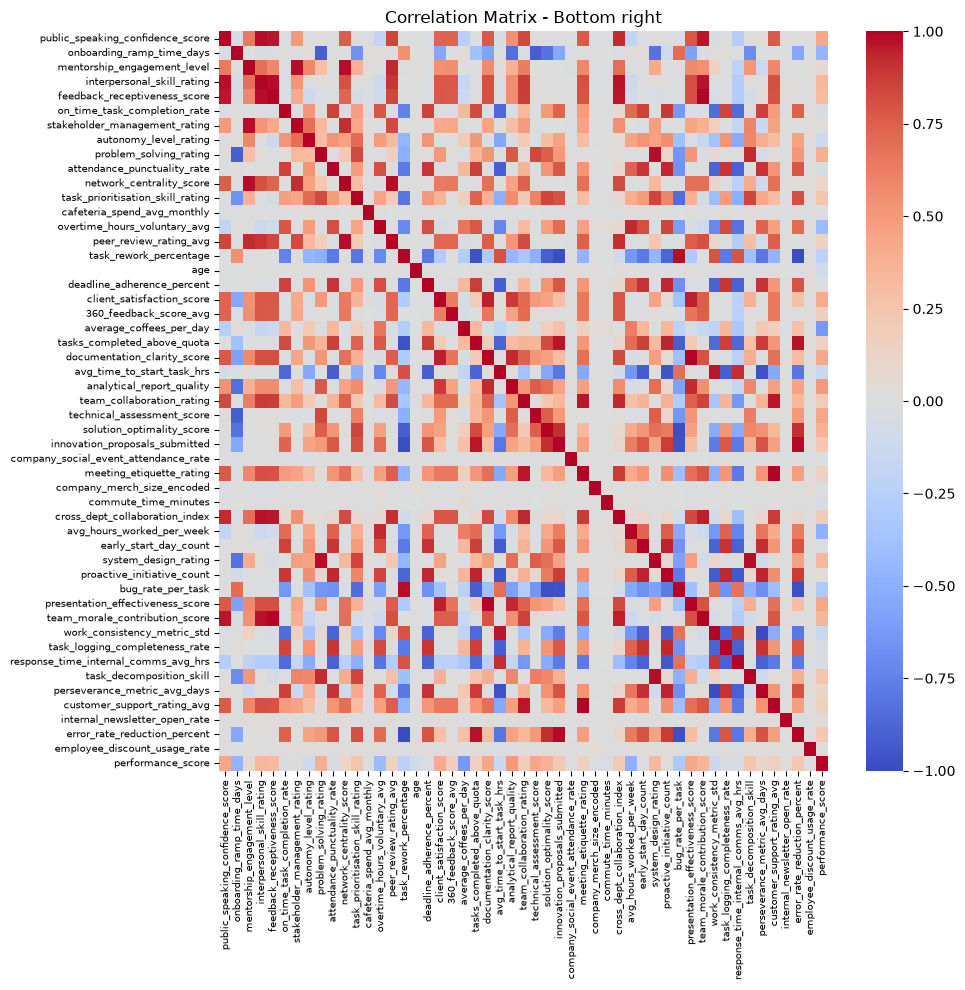

In [70]:

# split the correlation matrix into four quadrants because the main one is hard to read 
mid = len(correlations) // 2

quadrants = [
    correlations.iloc[:mid, :mid],  # top left
    correlations.iloc[:mid, mid:],  # top right
    correlations.iloc[mid:, :mid],  # bottom left
    correlations.iloc[mid:, mid:]   # bottom right
]

titles = ["Top left", "Top right", "Bottom left", "Bottom right"]

for quadrant, title in zip(quadrants, titles):
    plt.figure(figsize=(10, 10))
    seaborn.heatmap(
        quadrant,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        xticklabels=1,
        yticklabels=1
    )
    plt.title(f"Correlation Matrix - {title}")
    plt.xticks(rotation=90, fontsize=7)
    plt.yticks(fontsize=7)
    plt.tight_layout()
    plt.show()


### Subtask 2: Select an appropriate threshold to apply to the correlation coefficient, and hence determine which features to keep. Comment on how you selected the threshold, referring to the heatmap if applicable.

churn_risk_score_inverted               0.709911
solution_creativity_score               0.642462
learning_adaptability_metric            0.636284
average_coffees_per_day                 0.628774
critical_thinking_index                 0.606247
logic_test_score                        0.594652
complex_task_efficiency                 0.587466
analytical_report_quality               0.494932
avg_hours_worked_per_week               0.476822
onboarding_ramp_time_days               0.465643
code_review_effectiveness               0.464359
quantitative_analysis_score             0.459721
technical_assessment_score              0.433338
public_speaking_confidence_score        0.432282
email_sentiment_avg_positive            0.432244
new_tool_adoption_speed                 0.431505
presentation_effectiveness_score        0.424200
documentation_clarity_score             0.424144
communication_clarity_index             0.424144
overtime_hours_voluntary_avg            0.420703
client_satisfaction_

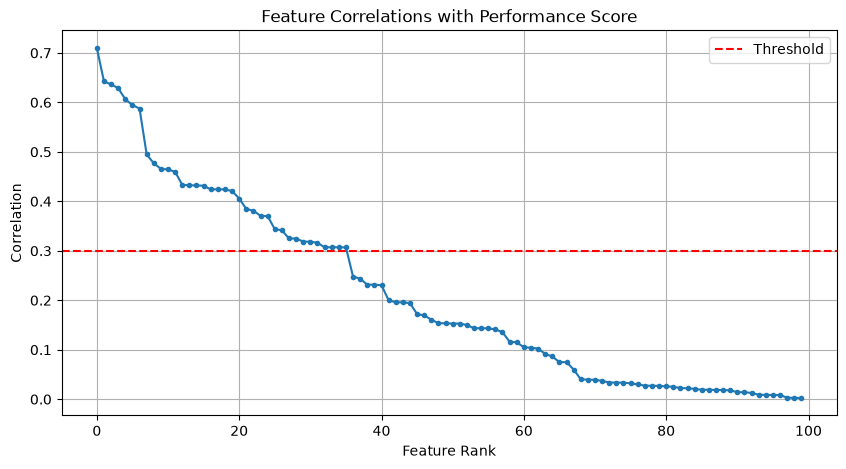

In [71]:
target_corrs = correlations["performance_score"].drop("performance_score") # exclude the correlation with itself
target_corrs = target_corrs.abs().sort_values(ascending=False)
print(target_corrs.to_string())

plt.figure(figsize=(10, 5))
plt.plot(target_corrs.values, marker=".")
plt.axhline(y = 0.30, color = "red", linestyle = "--", label = "Threshold")
plt.legend()
plt.xlabel("Feature Rank")
plt.ylabel("Correlation")
plt.title("Feature Correlations with Performance Score")
plt.grid()
plt.show()

I chose a correlation threshold of **0.30**, based on the observed correlations with performance_score. From the sorted correlation values, there is a noticeable drop from approximately 0.307 to 0.248, making 0.30 a reasonable cut-off point, as other earlier gaps would involve removing too many features. 

The heatmap also shows correlations between predictive features, which may indicate redundancy. However, the selection threshold is based specifically on each feature's correlation with performance_score.

This threshold retains 36 features while removing 64 features with weaker relationships to the target. 

One limitation of this approach is that features with weak individual correlations may still provide useful information when combined with other features.

In [72]:
threshold = 0.30

selected_features = target_corrs[target_corrs > threshold].index
selected_indices = [list(filter_feature_names).index(feature) for feature in selected_features]

X_train_selected = X_train_filter_preprocessed[:, selected_indices]
X_test_selected = X_test_filter_preprocessed[:, selected_indices]

### Subtask 3: Train a neural network on the selected features to predict the employee performance score, and then use the trained network on the test subset to compute the root mean square error (RMSE).

In [73]:
model_filter = MLPRegressor(
    hidden_layer_sizes = (100,50), # 100,50 example taken from lecture slides
    random_state = 4,
    max_iter = 1000,
    early_stopping = True
)

model_filter.fit(X_train_selected, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",4
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by atleast ``tol`` for ``n_iter_no_change`` consecutive epochs.Only effective when solver='sgd' or 'adam'.",True
,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when sol

In [74]:
y_pred_filter = model_filter.predict(X_test_selected) # use the trained network on the test subset

# now calculatre RMSE 
filter_rmse = np.sqrt(mean_squared_error(y_test, y_pred_filter))
print("FILTER RMSE:", filter_rmse)

FILTER RMSE: 4.687933728873922


## Task 3: Wrapper Methods

### Subtask 1: Use Sequential Forward Selection (SFS) and Sequential Backward Selection (SBS) to obtain a maximum of 40 features in each case. Plot the RMSE against the number of features for both SFS and SBS, and use the shape of curves to justify your choise of the number of features.

In [18]:
# Get the feature names after encoding
preprocessing_wrapper_featselect = clone(preprocessing_pipeline)
preprocessing_wrapper_featselect.fit(X_train)

wrapper_feature_names = list(
    preprocessing_wrapper_featselect.named_steps["encoding"].get_feature_names_out()
)

# now prepare structures for cross-validation
model_wrapper = MLPRegressor(
    hidden_layer_sizes = (100,50),
    max_iter = 1000,
    early_stopping = True,
    random_state = 4
)

cv = KFold(n_splits = 5, shuffle = True, random_state = 4)
def evaluate_subset(candidate_subset):
    candidate_selection_pipeline = Pipeline([
        ("preprocessing", clone(preprocessing_pipeline)),
        ("selection", ColumnTransformer([
            ("selected", "passthrough", candidate_subset)
        ], remainder = "drop")),
        ("model", clone(model_wrapper))
    ])

    scores = cross_val_score(
        candidate_selection_pipeline,
        X_train,
        y_train,
        cv = cv,
        scoring = "neg_root_mean_squared_error",
        n_jobs = -1
    )

    return -scores.mean()

In [19]:
# the steps to implement SFS and SBS where taken directly from the notes
# SFS:
# Step 1: Start with an empty feature set
selected_features_sfs = []
sfs_results = []

# Step 6: Repeat steps 2 to 5 until the stopping condition is reached (40 features selected)
while len(selected_features_sfs) < 40:
    scores = {}

    # Step 4: Repeat steps 2 and 3 for all features not already in the set
    for feature in range(len(wrapper_feature_names)):
        if feature in selected_features_sfs: continue

        # step 2: Temporarily add a feature to the set 
        candidate_subset = selected_features_sfs + [feature]

        # Step 3: Train the model and Compute the evaluation metric and store it
        rmse = evaluate_subset(candidate_subset)
        scores[feature] = rmse

    # Step 5: Check which added feature gave the best evaluation metric and add it to the set permanently.
    best_feature = min(scores, key = scores.get)
    selected_features_sfs.append(best_feature)

    sfs_results.append((
        len(selected_features_sfs), # number of features
        scores[best_feature], # RMSE for that n of features
        selected_features_sfs.copy() # the list of selected features
    ))

In [21]:
# SBS:
# Step 1: Start with a full feature set
selected_features_sbs = list(range(len(wrapper_feature_names)))
sbs_results = []

# Step 6: Repeat steps 2 to 5 until the stopping condition is reached (1 feature left)
while len(selected_features_sbs) > 1:
    scores = {}

    # Step 4: Repeat steps 2 and 3 for all features already in the set
    for feature in selected_features_sbs:

        # Step 2: Temporarily remove a feature from the set 
        candidate_subset = [f for f in selected_features_sbs if f != feature]

        # Step 3: Train the model and Compute the evaluation metric and store it
        rmse = evaluate_subset(candidate_subset)

        scores[feature] = rmse

    # Step 5: Check which removed feature gave the best evaluation metric and remove it from the set permanently
    best_feature = min(scores, key = scores.get)
    selected_features_sbs.remove(best_feature)

    if len(selected_features_sbs) <= 40:
        sbs_results.append((
            len(selected_features_sbs),
            scores[best_feature],
            selected_features_sbs.copy()
        ))

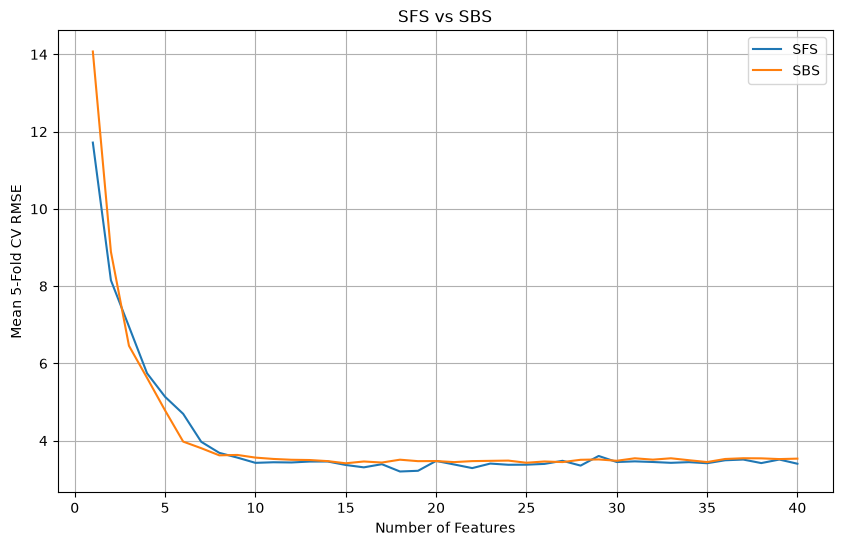

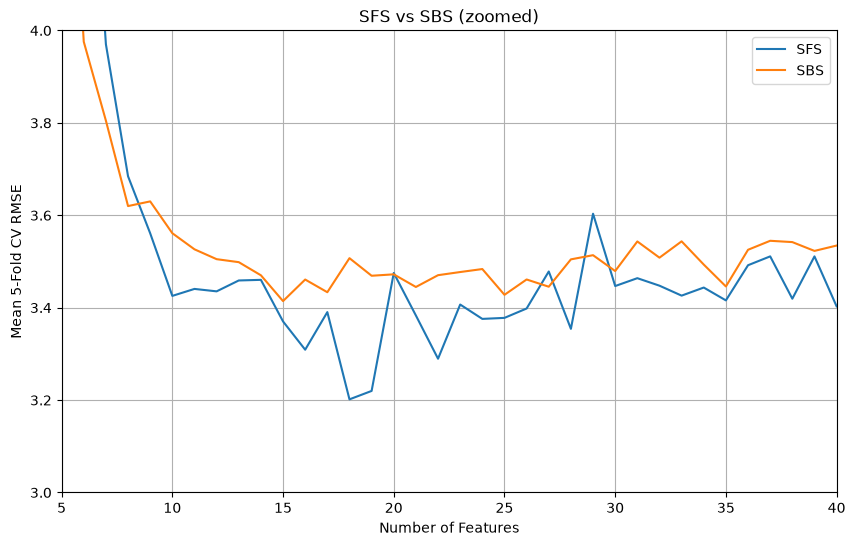

In [35]:
# Plot the RMSE against the number of features for both SFS and SBS
plt.figure(figsize = (10, 6))

plt.plot(
    [r[0] for r in sfs_results],
    [r[1] for r in sfs_results],
    label = "SFS"
)

plt.plot(
    [r[0] for r in sbs_results],
    [r[1] for r in sbs_results],
    label = "SBS"
)

plt.xlabel("Number of Features")
plt.ylabel("Mean 5-Fold CV RMSE")
plt.title("SFS vs SBS")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize = (10, 6))

plt.plot(
    [r[0] for r in sfs_results],
    [r[1] for r in sfs_results],
    label = "SFS"
)

plt.plot(
    [r[0] for r in sbs_results],
    [r[1] for r in sbs_results],
    label = "SBS"
)

plt.xlabel("Number of Features")
plt.ylabel("Mean 5-Fold CV RMSE")
plt.title("SFS vs SBS (zoomed)")
plt.ylim(3.0,4.0)
plt.xlim(5,40)
plt.legend()
plt.grid()
plt.show()

From the shape of the curves for SFS and SBS, one can see a sharp decline in RMSE as the number of features increases; however, after roughly 10-12 features, this decline slows drastically. Both SFS and SBS have a dipping point at which they reach their lowest RMSE after this initial slowdown, with SFS having a more pronounced dip. Since after this dip, both curves have an upward trend in RMSE,  I have considered these points when choosing the number of features for each method.

Since the dip occurs at approximately 15 features for SBS and 18 features for SFS, I chose those numbers for each of them respectively.

In [44]:
sfs_count = 18
sbs_count = 15

for result in sfs_results:
    if result[0] == sfs_count:
        chosen_n_sfs = result

for result in sbs_results:
    if result[0] == sbs_count:
        chosen_n_sbs = result

### Subtask 2: Discuss the strengths and limitations of SFS and of SBS in this context.

As SFS and SBS are both heuristic variants of Wrapper methods, I will first discuss the strengths and limitations that the heuristic wrapper method houses, and will then specify into the strengths and limitations that the individual methods have. 

#### Wrapper Methods (Heuristic Variants)
**Strengths** 
- **Accuracy**: Wrapper methods typically achieve high prediction accuracy because they identify the feature combinations which improve the neural network's performance when predicting employee performance scores. This makes the selected features specifically suited to the model being used. 

- **Reduced Search Space:** Since we have 100 features, the number of possible subset combinations in the search space would be $2^{100}$. In my experience, the neural network I have specified takes roughly 10 seconds to train, meaning had I started 30 trillion times the current age of the universe, I might have made it in time for submission. Therefore, heuristic wrapper methods are particularly advantageous when working with a large number of features, as their greedy approach significantly reduces the search space by selecting the best feature addition or removal at each step.


**Limitations**
- **Computationally Demanding:** The neural network must be trained for each candidate feature subset considered during the selection process. Given we had 100 features to work with, run-time was considerably long compared to other methods. This computational cost increased further because cross-validation was used to improve the reliability of candidate subset evaluations and could thus subsequently improve generalization. Since the goal of Task 6 was to eventually evaluate the predictions of the model on unseen data, in my eyes, this computational demand was worth it, especially since only 5 folds were used, and scikit-learn has very handy built-in parallel processing methods which I used to evaluate the five folds in parallel. 

- **Getting stuck at local minima:** Since a greedy approach is used, heuristic wrapper methods are susceptible to getting stuck at a local minimum instead of converging towards the global minimum. This was particularly relevant when searching among combinations of our 100 features, since evaluating only a small portion of the search space means potentially better subsets may be overlooked.

#### Individual Method: Sequential Forward Selection (SFS)
**Strengths** 
- **Lower Computational Cost Relative to SBS**: While Wrapper methods are generally computationally intensive, SFS alleviates some of this by starting with an empty set and thus requires less selection iterations to arrive to the final subset size. In this case, selecting a maximum of 40 features from 100 requires 40 iterations for SFS, whereas SBS requires 99 iterations to reduce the original 100 features to 1

    Since each iteration evaluates all possible feature additions or removals, this translates into:

    $N_{\text{SFS}} = \sum_{i=0}^{39}(100-i) = 3220$

    $N_{\text{SBS}} = \sum_{i=0}^{98}(100-i) = 5049$


    Therefore, SFS requires fewer candidate subset evaluations, providing a computational advantage over SBS. 

**Limitations**
- ***Irreversible feature selection:** Once a feature is selected because it produces the lowest RMSE among the available additions, it cannot be removed, even if it later becomes less useful when combined with subsequently selected features. With up to 40 features being selected, poor early decisions could affect the predictive power of the final subset. It is for this reason that variants such as Sequential Fordward Floating Selection (SFFS) check for the possiblity of improvement when removing an already chosen feature. 

#### Individual Method: Sequential Backward Selection (SBS)
**Strengths** 
- **Accounts for Joint Predictive Power**: Unlike SFS, SBS starts with all 100 features, allowing the neural network to initially consider the combination of all features. This can help retain features that provide little predictive value individually but contribute significantly when combined with other features.

**Limitations**
- **Irreversible Removal of important features:** Similarly to SFS, SBS can end up removing features which are later on important. However, this is occurs in an inverse way to SFS; while SFS may *not add* features which in later iterations have good performance, SBS may *remove* features which in later iterations have good performance. The removed feature may initially appear unnecessary in the larger subset but would become useful once other features are removed. The key distinction is that SFS can still reconsider previously unselected features in subsequent iterations until the target subset size is reached, whereas SBS permanently excludes removed features from consideration. Since SBS reduces the feature set from 100 to at most 40, it makes many irreversible removal decisions, potentially overlooking better combinations. This is why variants such as Sequential Backward Floating Selection (SBFS) check for the possibility of improvement when *re-adding* an already removed feature. 

### Subtask 3: For each of the SFS and the SBS feature selections, train a neural network using the same dataset split as Task 2 to predict the employee performance score, and compute the RMSE on the test subset.

In [46]:
# SFS
preprocessing_wrapper = clone(preprocessing_pipeline)

X_train_wrapper_preprocessed = preprocessing_wrapper.fit_transform(X_train)
X_test_wrapper_preprocessed= preprocessing_wrapper.transform(X_test)

X_train_sfs = X_train_wrapper_preprocessed[:, chosen_n_sfs[2]]
X_test_sfs = X_test_wrapper_preprocessed[:, chosen_n_sfs[2]]

model_sfs = MLPRegressor(
    hidden_layer_sizes = (100,50),
    random_state = 4,
    max_iter = 1000,
    early_stopping = True
)

model_sfs.fit(X_train_sfs, y_train)

y_pred_sfs = model_sfs.predict(X_test_sfs)

sfs_rmse = np.sqrt(mean_squared_error(y_test, y_pred_sfs))

print("SFS RMSE:", sfs_rmse)

SFS RMSE: 2.940682815971215


In [47]:
# SBS
X_train_sbs = X_train_wrapper_preprocessed[:, chosen_n_sbs[2]]
X_test_sbs = X_test_wrapper_preprocessed[:, chosen_n_sbs[2]]

model_sbs = MLPRegressor(
    hidden_layer_sizes = (100,50),
    random_state = 4,
    max_iter = 1000,
    early_stopping = True
)

model_sbs.fit(X_train_sbs, y_train)

y_pred_sbs = model_sbs.predict(X_test_sbs)

sbs_rmse = np.sqrt(mean_squared_error(y_test, y_pred_sbs))

print("SBS RMSE:", sbs_rmse)

SBS RMSE: 3.1658851312688157


## Task 4: Feature Projection

### Subtask 1: Use Principal Component Analysis (PCA) to reproject the features to principal components, and produce a plot to show the variance ratios of the principal components.

Before applying PCA, I replaced MinMaxScaler with StandardScaler so to perform standardization rather than the normalization required in task 1. However, I applied StandardScaler only to the remaining numerical features in the encoding pipeline, leaving the one-hot encoded categorical features unchanged so to preserve their binary representation.

Although PCA does not **require** standardization, and using standardization would slightly alter the comparison fairness in Task 5, restricting PCA to use normalization is also an alteration of comparison fairness as it may perform more poorly with it. 

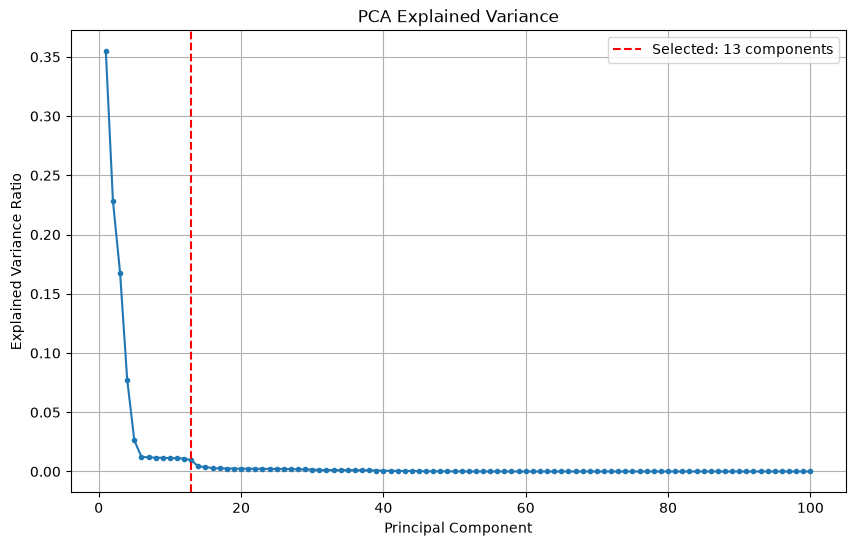

In [48]:
preprocessing_pca = clone(preprocessing_pipeline)

preprocessing_pca.set_params(
    normalization = "passthrough",
    encoding__remainder = StandardScaler()
)

X_train_pca_preprocessed = preprocessing_pca.fit_transform(X_train)
X_test_pca_preprocessed = preprocessing_pca.transform(X_test)

# Apply PCA 
pca = PCA()
pca.fit(X_train_pca_preprocessed)

# Get variance ratios
variance_ratios = pca.explained_variance_ratio_

# Plot explained variance
plt.figure(figsize = (10, 6))

plt.plot(
    range(1, len(variance_ratios) + 1),
    variance_ratios,
    marker = "."
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance")
plt.grid()
plt.axvline(x = 13, color = "red", linestyle = "--", label = "Selected: 13 components")
plt.legend()
plt.show()

### Subtask 2: Select an appropriate cut-off point and remove features beyond it. You can use a cumulative explained variance plot for this justification.

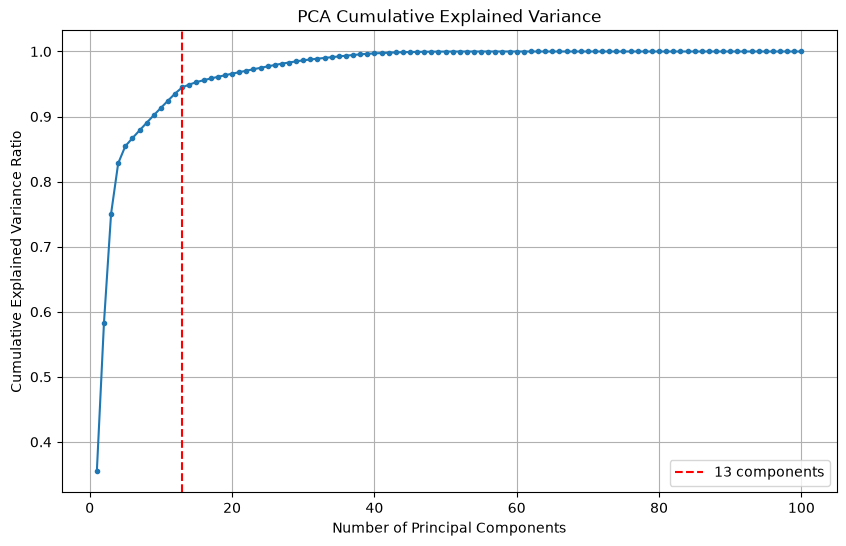

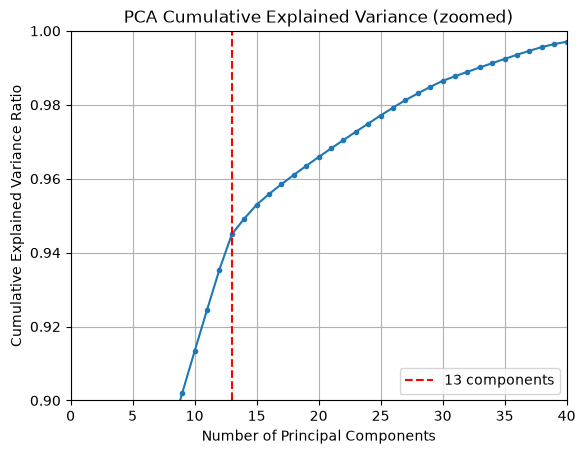

Explained variance at 13 components: 94.50%


In [49]:
# Calculate cumulative explained variance
cumulative_variance = np.cumsum(variance_ratios)

# Plot cumulative explained variance
plt.figure(figsize = (10, 6))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker = "."
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.title("PCA Cumulative Explained Variance")
plt.grid()
plt.axvline(x = 13, color = "red", linestyle = "--", label = "13 components")
plt.legend()
plt.show()

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker = "."
)
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.title("PCA Cumulative Explained Variance (zoomed)")
plt.xlim(0, 40)
plt.ylim(0.90, 1.00)
plt.grid()
plt.axvline(x = 13, color = "red", linestyle = "--", label = "13 components")
plt. legend()
plt.show()

print(f"Explained variance at 13 components: {cumulative_variance[12]:.2%}")

In [50]:
# apply cutoff (13 components) 
pca_selected = PCA(n_components = 13)

X_train_pca = pca_selected.fit_transform(X_train_pca_preprocessed)
X_test_pca = pca_selected.transform(X_test_pca_preprocessed)

print("Original features:", X_train_pca_preprocessed.shape[1])
print("Selected components:", X_train_pca.shape[1])
print("Variance retained:", pca_selected.explained_variance_ratio_.sum())

Original features: 100
Selected components: 13
Variance retained: 0.9449509329811553


### Subtask 3: Comment on how you picked the cut-off point.


I chose a cut off of **13 principal components** based on the cumulative explained variance plot. The curve rises relatively quickly up to approximately 13 components, after which the gain per component visibly drops, and one sees diminishing returns with regards to variance gain. Although there is another elbow at roughly 4 components, which alone retain roughly 82.5% of the variance, choosing the cut-off point there would discard too much information. 

Thus this cutoff reduces the dimensionality from 100 to only 13 while preserving **94.50%** of the data's variance.

### Subtask 4: Discuss the strengths and limitations of PCA in this context

#### Strengths:

- **Dimensionality Reduction:** PCA allows reduction of the data to just 13 principal components, while still retaining 94.5% of the variance of the dataset. This also reduces computational cost, which is not exactly a concern in this case since we are only training one neural network.

- **Reduced Risk of Overfitting**: By discarding components without much contribution to the overall variance, we reduce the risk of overfitting due to the model learning noise from those components.

#### Limitations: 
- **Standardization**: In this assignment, the fact that PCA is suited better with *standardization* due to sensitivity in differences in feature scales, means it has to deviate slightly from the other methods which from the task 1 instructions use *normalization*. This is a limitation moreso in the sense that when comparing the different methods, it would be slightly unfair, rather than a limitation of the method in and of itself. As discussed in the beginning of this task, however, restricting PCA performance by enforcing normalization would be also be unfair when comapring RMSEs. 

- **Handles categorical features poorly**: PCA treats numerically encoded categorical features as continues numerical features, even though the categorical features have discrete values; doing so may result in false numerical relationships. This is especially a problem for cases where one hot encoding is used, like how I have decided to proceed in task 1, since the resulting binary features have lower variance than the standardized numerical features; thus contributing less to the principle components. As discussed earlier, despite this, I have chosen to leave the one-hot encoded features unchanged so to preserve their binary representation and avoid disproportionately scaling rare categories. There are many resources online regarding handling of this issue, using techniques such as Multiple Correspondence Analysis (MCA) and Factor Analysis of Mixed Data (FAMD), however I felt that it was outside the scope of this assignment to implement these. 

- **Variance is not necessarily indicative of Predictive Power:** Variance simply measures how widely the data spreads out in a direction, while ignoring the target feature. While higher variance may indicate an increase in the amount of information about the dataset we can learn from a component, it does not guarantee that the information learned is useful for predicting the target of employee performance.


### Subtask 5: Train a neural network using the same dataset split as Task 2 to predict the employee performance score, and compute the RMSE on the test subset.

In [51]:
model_pca = MLPRegressor(
    hidden_layer_sizes = (100,50),
    random_state = 4,
    max_iter = 1000,
    early_stopping = True
)

model_pca.fit(X_train_pca, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",4
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by atleast ``tol`` for ``n_iter_no_change`` consecutive epochs.Only effective when solver='sgd' or 'adam'.",True
,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when sol

In [52]:
# Predict using the test data
y_pred_pca = model_pca.predict(X_test_pca)

# Calculate test RMSE
pca_rmse = np.sqrt(mean_squared_error(y_test, y_pred_pca))

print("PCA RMSE:", pca_rmse)

PCA RMSE: 4.576986180080602


## Task 5: Comparison

### Subtask 1: Compare the RMSE for the four methods used (filter, SFS, SBS, PCA).


$$
\begin{aligned}
\text{Filter-based Method RMSE} &= 4.688 \\
\text{Sequential Forward Selection (SFS) RMSE} &= 2.941 \\
\text{Sequential Backward Selection (SBS) RMSE} &= 3.166 \\
\text{Principal Component Analysis (PCA) RMSE} &= 4.577
\end{aligned}
$$

### Subtask 2: Discuss which methods produce the best results and why.

From the RMSE results seen above, both wrapper methods achieved better predictive performance than PCA and the filter-based method, with Sequential Forward Selection (SFS) achieving the lowest test RMSE of 2.941, followed closely by Sequential Backward Selection (SBS) achieving 3.166. 

From the strengths of the wrapper methods discussed in their respective task, this comes as no surprise. The fact that wrapper based methods evaluate different feature subsets based on neural network performance allows them to identify combinations of features which are actually useful for predicting the employee performance scores. 

In contrast, PCA selects components based on variance; the limitations of PCA have been discussed in the previous task, especially in relation to why higher variance of a principal component does not necessarily indicate higher predictive power. 

The Filter-based method performed the poorest, however not by such a degree that one can say that PCA would consistently perform better on unseen data for this particular dataset and target feature. The Filter-based method, however, may have performed more poorly than wrapper methods as it evaluates each feature independently, when in reality, features may provide more predictive value only when evaluated in tandem with other features. This fact of features having high predictive power in combination with others is precisely what wrapper methods take advantage of which the Filter-based method ignores. 

There is also a more interesting question at hand however, and that is the comparison of the wrapper methods themselves. SFS achieved the lower RMSE of 2.941, compared with 3.166 achieved by SBS. 

The reason for this is quite difficult to answer with certainty. Although cross-validation made the selection process more reliable, the final test RMSEs compared here each come from a single trained network evaluated on a single test split, so some of the difference between them may be random variation. Besides this, one possible explanation would lie in the different search strategies. SFS starts with an empty feature set which it progressively fills, while SBS's feature set starts with all the features from the get-go, and progressively removes features from the set. These different approaches may result in different combinations of features; why the different combinations of features work better, or why a particular approach may be more likely to choose successful combinations would require closer analysis of the selected subsets, which is beyond the scope of this assignment

However, in my case, SFS may have followed a search path resulting in more useful combinations of features, hence the lower RMSE. It must be emphasized that the RMSE achieved on this particular test subset alone cannot verify that SFS will perform better than SBS on other unseen data. 

Overall, Sequential Forward Selection achieved the lowest test RMSE and would therefore be my preferred model for Task 6.

## Task 6: Prediction on unlabelled samples

$$
\text{Model Chosen: MLPRegressor with SFS-selected features}
$$
From the results obtained which are shown in task 5, I have decided to use Sequential Forward Selection, as it achieved the lowest test RMSE of 2.941. 

Since RMSE measures the difference between the predicted and actual values of the target feature, performance scores, a lower RMSE indicates the model is more accurate. Although this does not guarantee the model will be the best at predicting employee performance on unseen data, the RMSE value is the best piece of evidence I had for my decision. 

I have also decided to, as mentioned in the assignment spec, retrain the model using the entire available dataset. Since the test-training split was done randomly, it can be assumed that the data used for testing is of similar quality and is thus also suitable for training the final model. It is for this reason that I have retrained the model, as using more training data would generally be expected to improve generalization to the unlabelled data, even if there is a possibility for generalization to stay the same or even worsen.

### Subtask 1: Modification of the model and retraining using the whole dataset

In [53]:
# Prepare the entire labelled dataset
X_full = raw_data.drop(columns = features_to_remove)
y_full = raw_data["performance_score"]

X_full = X_full.replace("?", np.nan)
X_full[numeric_features] = X_full[numeric_features].apply(pd.to_numeric)

# preprocess using the full labelled dataset
preprocessing_task6 = clone(preprocessing_pipeline)
X_full_preprocessed = preprocessing_task6.fit_transform(X_full)

# select the 18 sfs features
X_full_sfs = X_full_preprocessed[:, chosen_n_sfs[2]]

In [54]:
# now retrain the neural network again
model_task6 = MLPRegressor(
    hidden_layer_sizes = (100,50),
    random_state = 4,
    max_iter = 1000,
    early_stopping = True
)

model_task6.fit(X_full_sfs, y_full)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",4
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by atleast ``tol`` for ``n_iter_no_change`` consecutive epochs.Only effective when solver='sgd' or 'adam'.",True
,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when sol

### Subtask 2: Make predictions of the employee performance scores for the data in unlabelled.csv. 

In [55]:
unlabelled_data = pd.read_csv("unlabelled.csv")

X_unlabelled = unlabelled_data[X_full.columns].copy()

X_unlabelled = X_unlabelled.replace("?", np.nan)
X_unlabelled[numeric_features] = X_unlabelled[numeric_features].apply(pd.to_numeric)

X_unlabelled_preprocessed = preprocessing_task6.transform(X_unlabelled)
X_unlabelled_sfs = X_unlabelled_preprocessed[:, chosen_n_sfs[2]]
y_pred_unlabelled = model_task6.predict(X_unlabelled_sfs)


task6_predictions = pd.DataFrame({
    "id": unlabelled_data["id"],
    "performance_score": y_pred_unlabelled
})

task6_predictions.to_csv("task6_predictions.csv", index= False)

print(task6_predictions.head())

      id  performance_score
0  13001          85.750857
1  13002          75.255568
2  13003          42.242564
3  13004          56.465198
4  13005          60.567002
